<a href="https://colab.research.google.com/github/abhinayakscs25-svg/BIS/blob/main/week_4_ant_colony.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best Route: [1, 2, 4, 3, 1]
Minimum Distance: 80


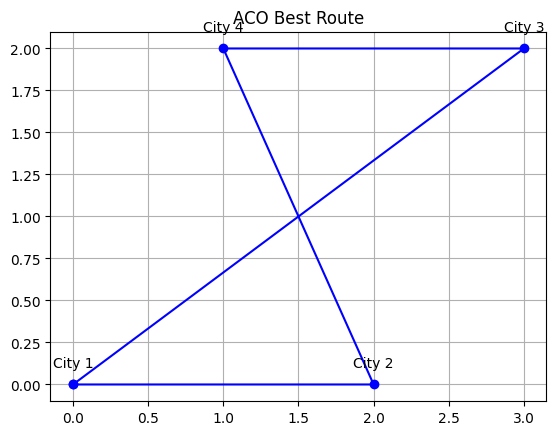

In [ ]:

import numpy as np
import random
import matplotlib.pyplot as plt

D = np.array([[0,10,15,20],
              [10,0,35,25],
              [15,35,0,30],
              [20,25,30,0]])

n = 4
pheromone = np.ones((n,n))
best, best_dist = None, float('inf')

for _ in range(100):
    for _ in range(10):
        path = [random.randrange(n)]
        while len(path) < n:
            i = path[-1]
            cities = [j for j in range(n) if j not in path]
            p = np.array([pheromone[i,j]/D[i,j] for j in cities])
            path.append(random.choices(cities, weights=p/p.sum())[0])

        dist = sum(D[path[i],path[(i+1)%n]] for i in range(n))
        if dist < best_dist:
            best, best_dist = path[:], dist
        for i in range(n):
            pheromone[path[i],path[(i+1)%n]] += 1/dist
    pheromone *= 0.9

best.append(best[0])
print("Best Route:", [x+1 for x in best])
print("Minimum Distance:", best_dist)

x = [0, 2, 3, 1]
y = [0, 0, 2, 2]
plt.plot([x[i] for i in best], [y[i] for i in best], 'bo-')
for i in range(n):
    plt.text(x[i], y[i]+0.1, f'City {i+1}', ha='center')
plt.title("ACO Best Route")
plt.grid()
plt.show()
